In [7]:
from tqdm import tqdm
from req_functions_from_ApproxSP import *
from generate_profiles import *
from mallows import *
import json
from impartial import *
import pandas as pd
from euclidean import *


**Mallows**

In [3]:
data_mallows_gain = []

n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []
    
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        
        for samples in range (100):
            cnt=0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:05<00:00,  1.05it/s]


In [4]:
df2 = pd.DataFrame(data_mallows_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preferences", "original matchings", "manipulated matchings", "benefit"])
df2.to_csv('mallows_gain.csv', index=False)

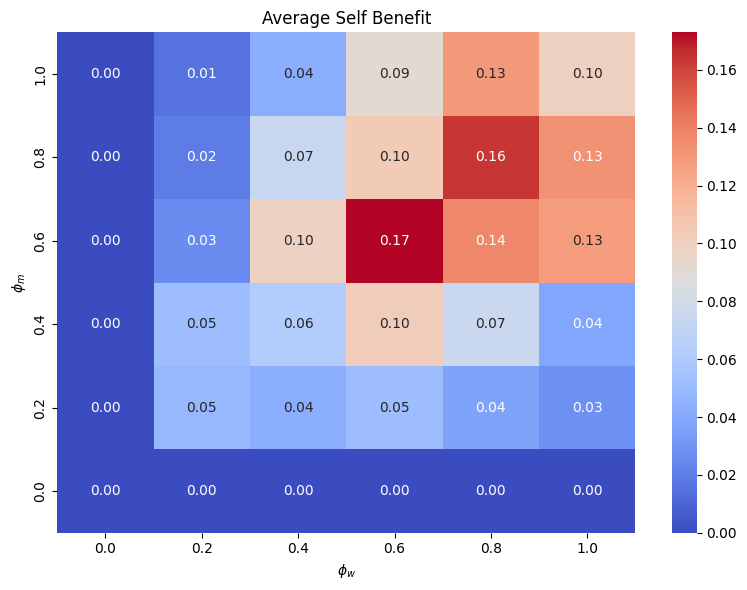

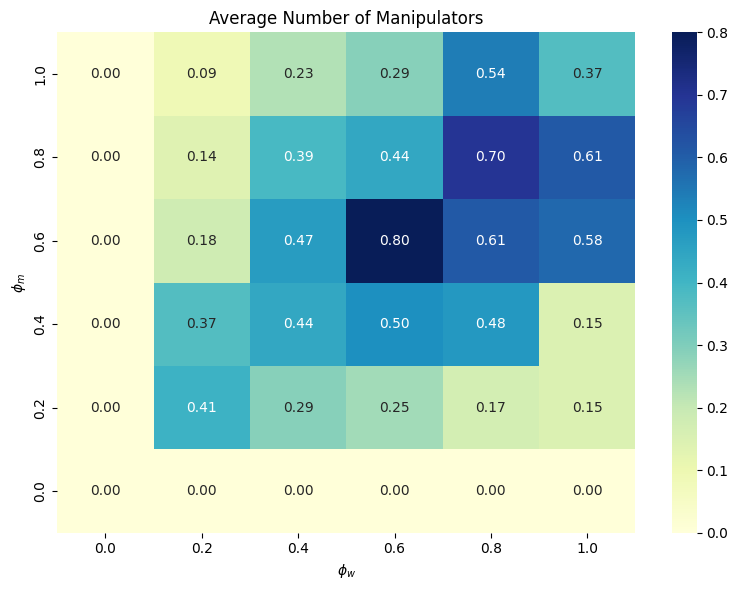

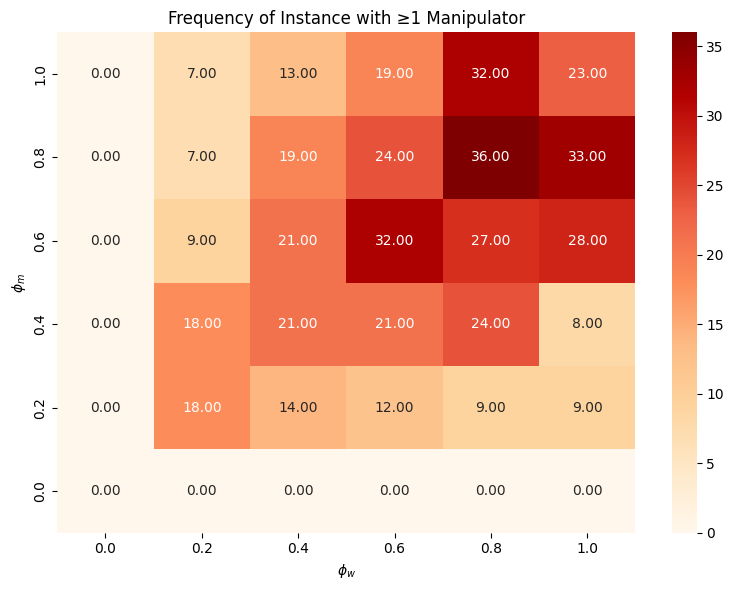

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


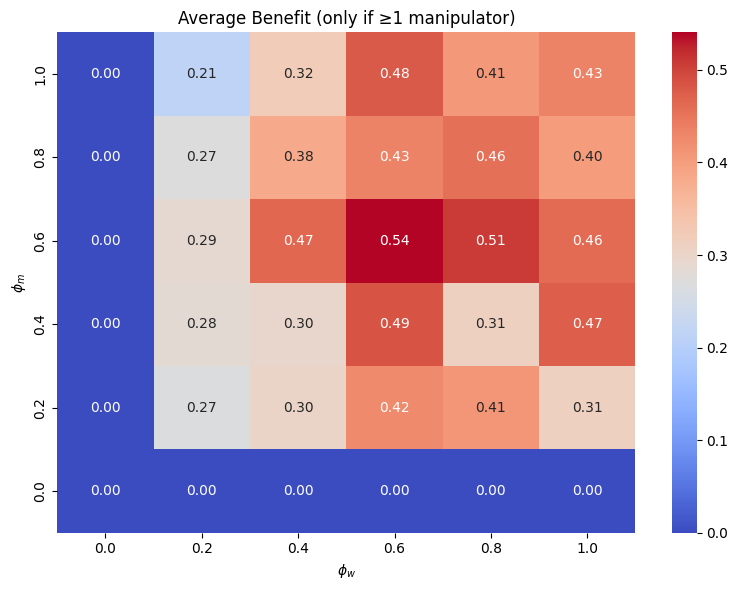

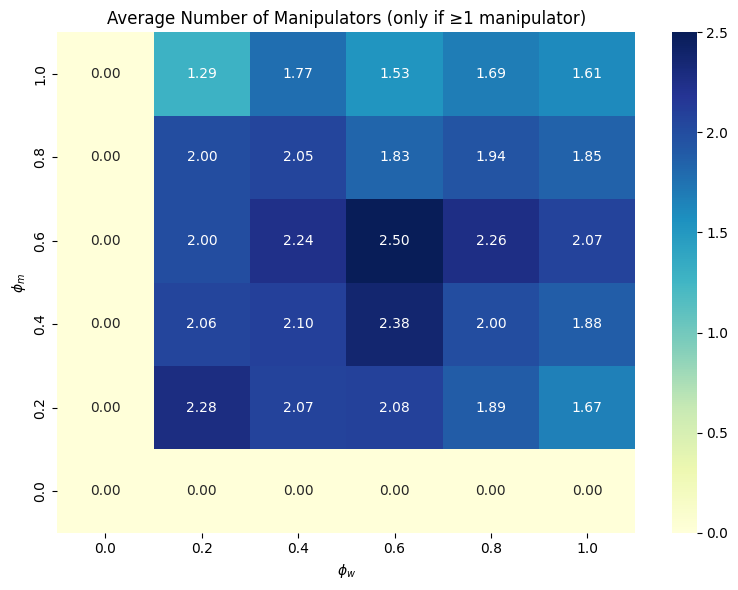

In [24]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Mallows MD**

In [5]:
data_mallows_MD_gain = []

n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []

    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]

        for samples in range (100):
            cnt=0
            pref = generate_mallows_asymmetric_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []

            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000

                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_MD_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:02<00:00,  2.57it/s]


In [6]:
df3 = pd.DataFrame(data_mallows_MD_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_MD_gain.csv', index=False)

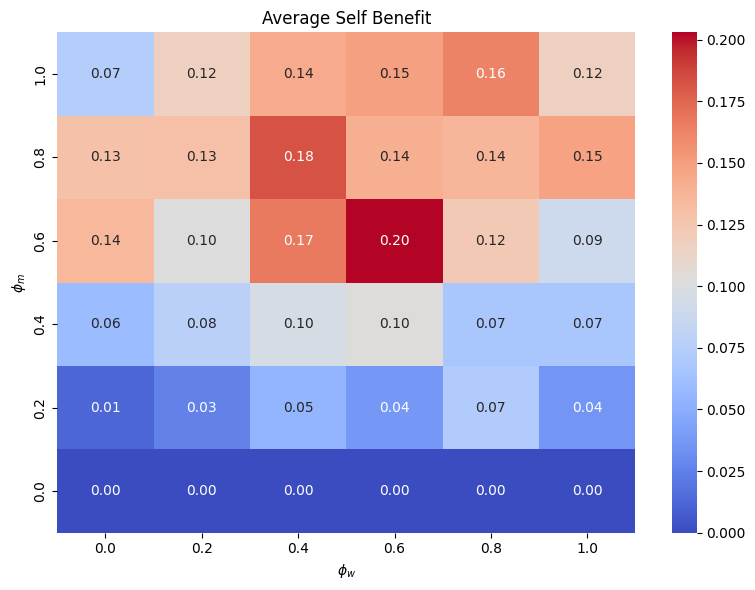

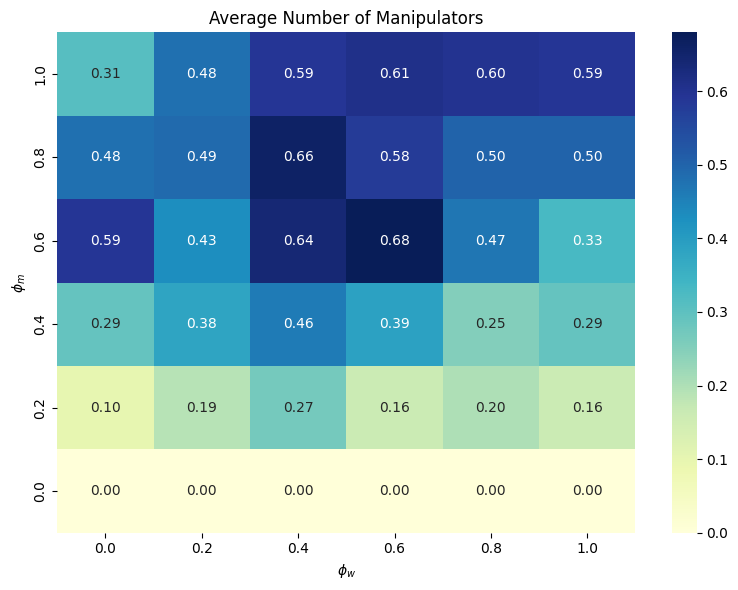

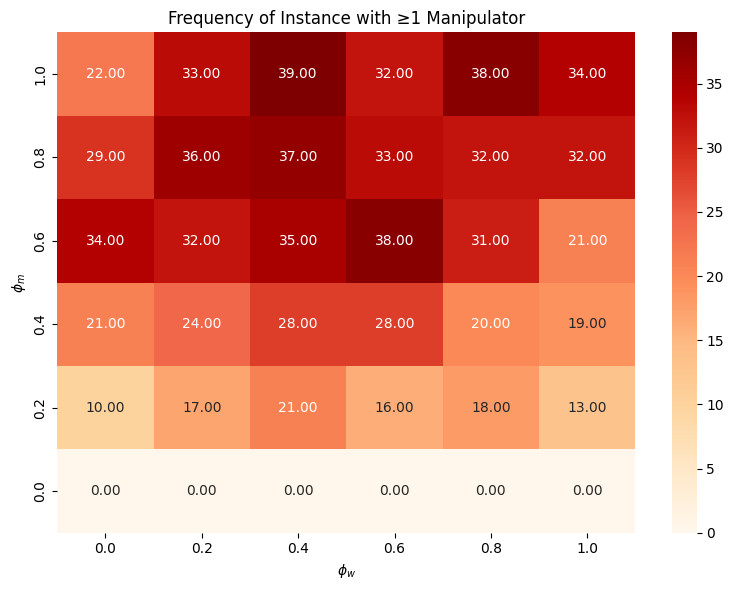

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MD_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_MD_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


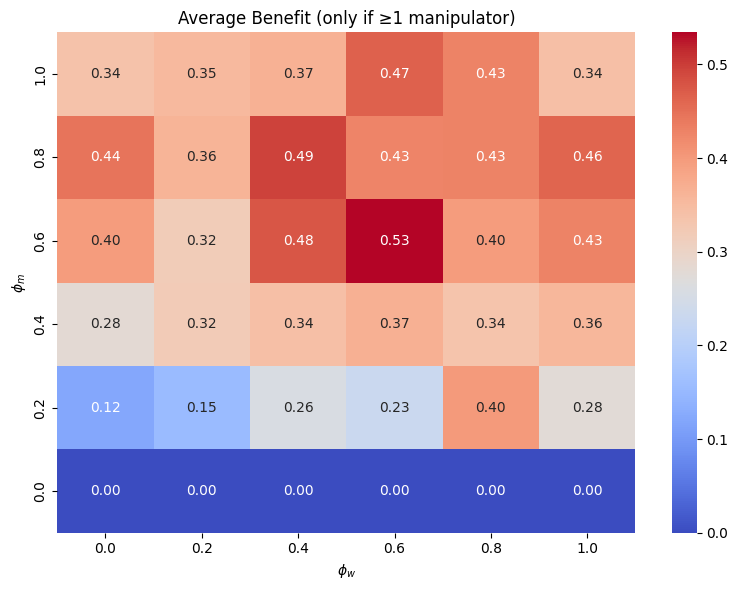

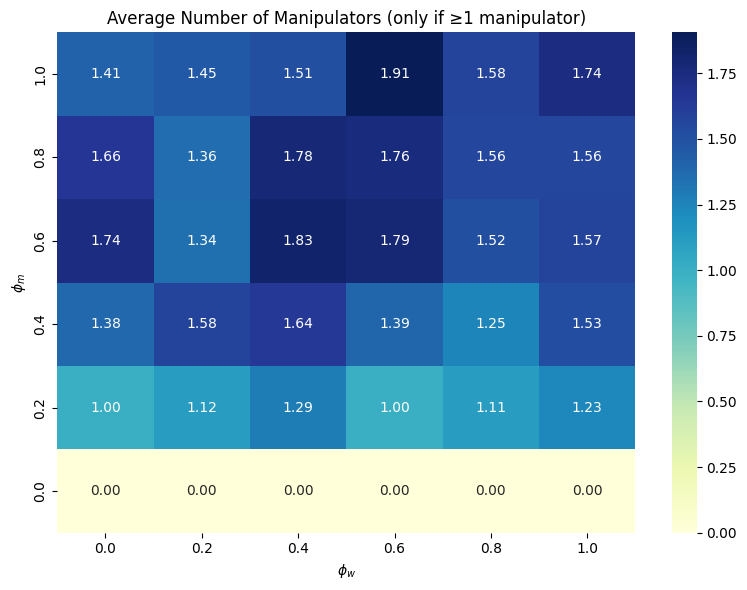

In [26]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Mallows Euclidean**

In [9]:
data_mallows_euclidean_gain = []

n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []

    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]

        for samples in range (100):
            cnt=0
            pref = generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []

            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000

                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]

                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_euclidean_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])


            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:04<00:00,  1.25it/s]


In [10]:
df3 = pd.DataFrame(data_mallows_euclidean_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_euclidean_gain.csv', index=False)

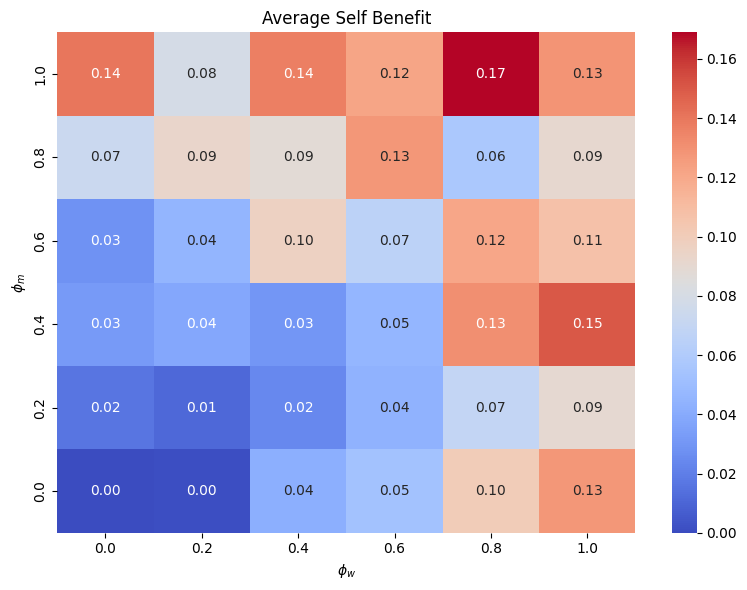

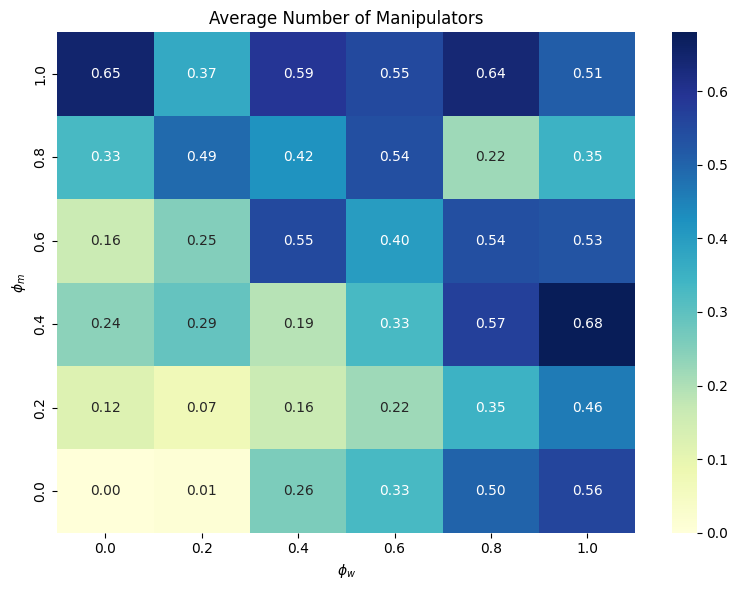

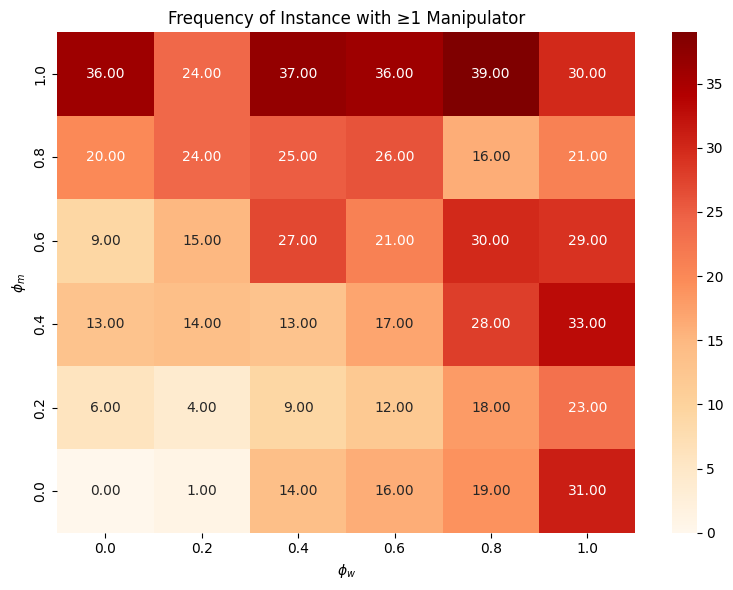

In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


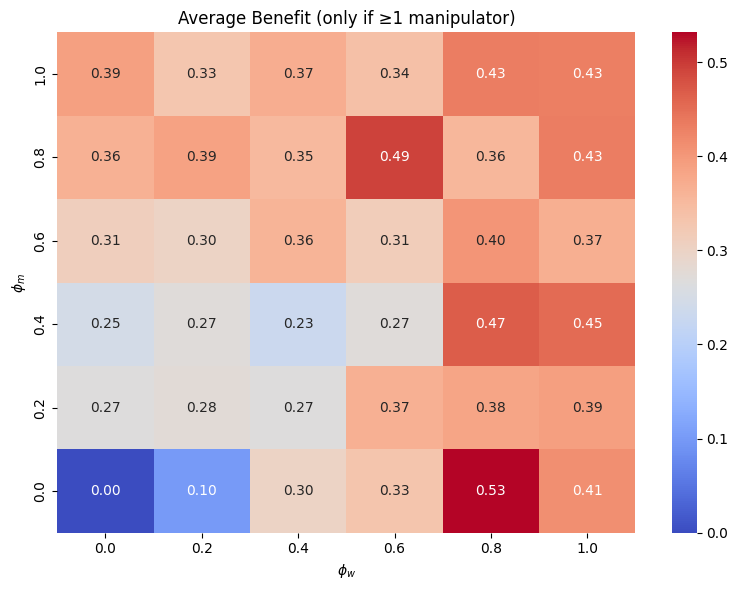

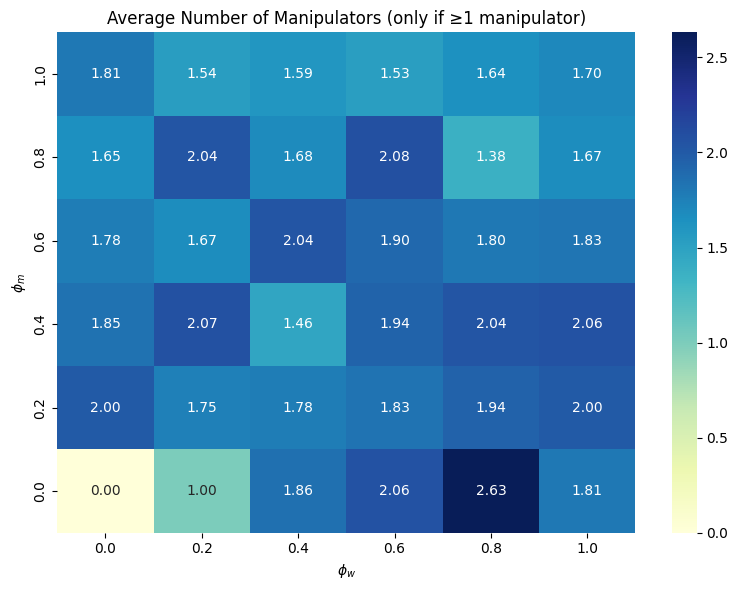

In [28]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Reverse Euclidean**

In [11]:
data_reverse_euclidean_gain = []

n=10
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for p in tqdm(p_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_reverse_euclidean_votes(n, d, 'uniform', 0.5, p)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_reverse_euclidean_gain.append([d, p, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:02<00:00,  1.76it/s]


In [12]:
df5 = pd.DataFrame(data_reverse_euclidean_gain, columns=["dimension", "proportion", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df5.to_csv('reverse_euclidean_gain.csv', index=False)

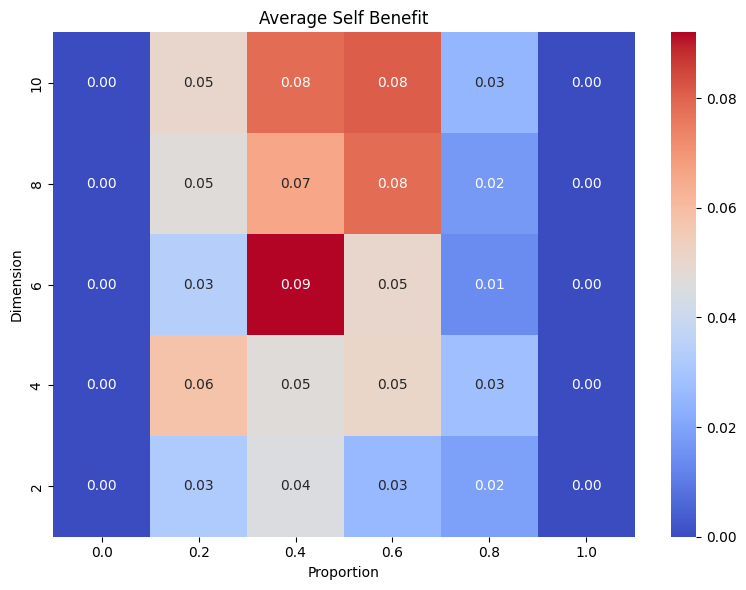

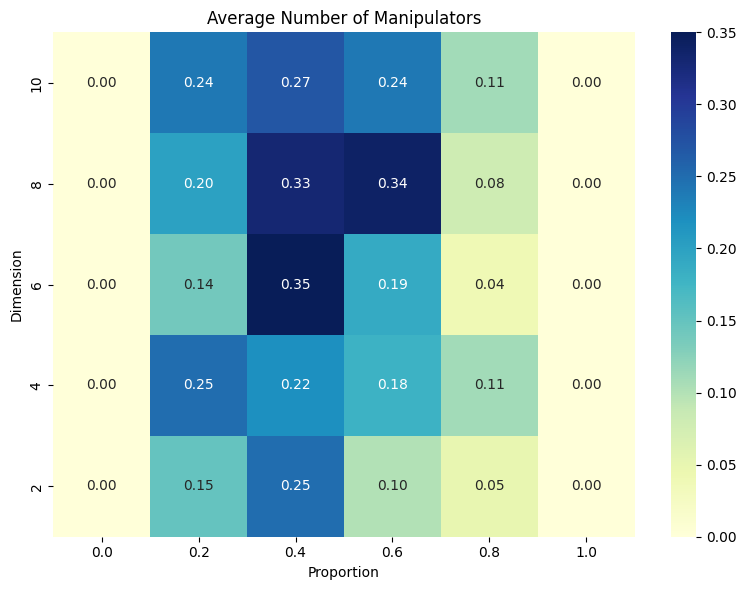

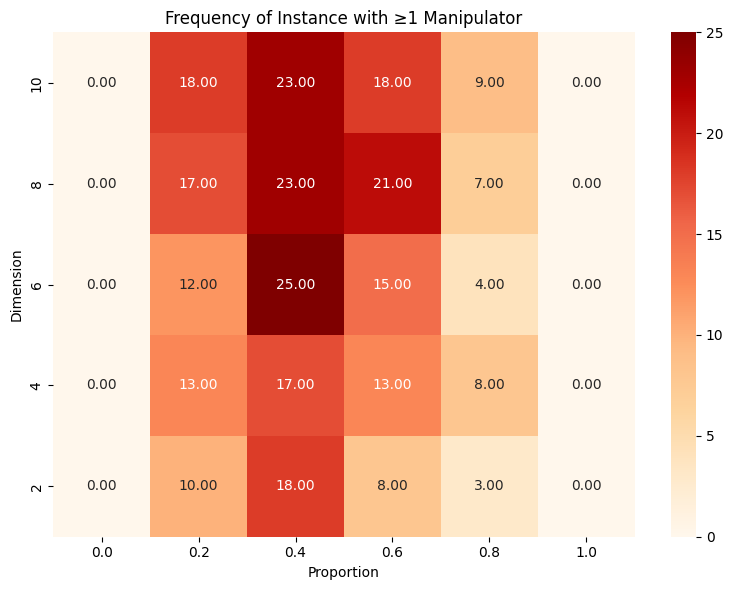

In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("reverse_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("reverse_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "proportion"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


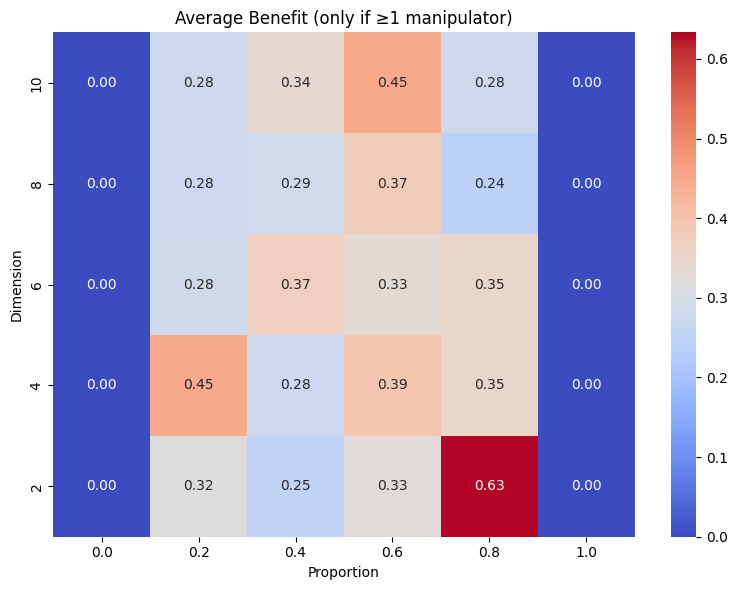

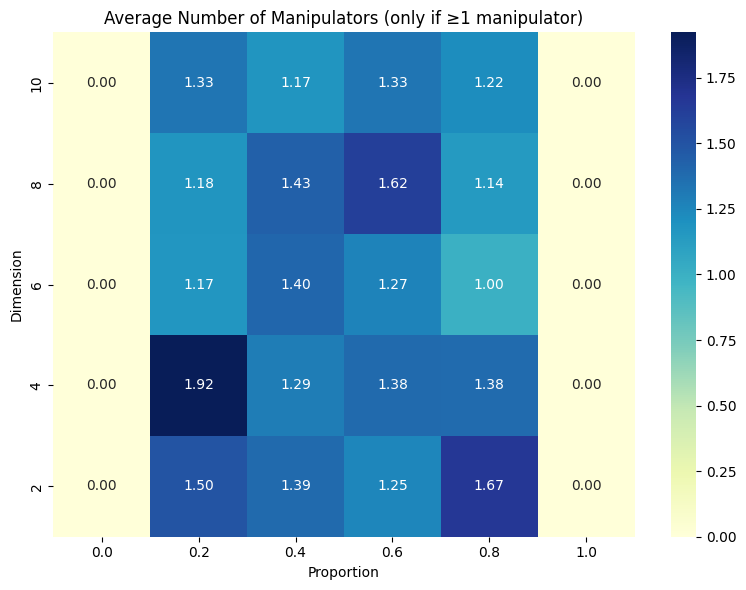

In [31]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "proportion"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "proportion"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "proportion"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "proportion"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "proportion"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "proportion"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="proportion", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="proportion", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Expectations Euclidean**

In [13]:
import numpy as np

def convert_to_builtin(obj):
    if isinstance(obj, dict):
        return {convert_to_builtin(k): convert_to_builtin(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_builtin(elem) for elem in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    else:
        return obj
    
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [38]:
data_expectations_euclidean_gain = []

n=10
std_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for std in tqdm(std_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_expectations_euclidean_gain.append([d, std, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:05<00:00,  1.07s/it]


In [39]:
df6 = pd.DataFrame(data_expectations_euclidean_gain, columns=["dimension", "std", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df6.to_csv('expectations_euclidean_gain.csv', index=False)

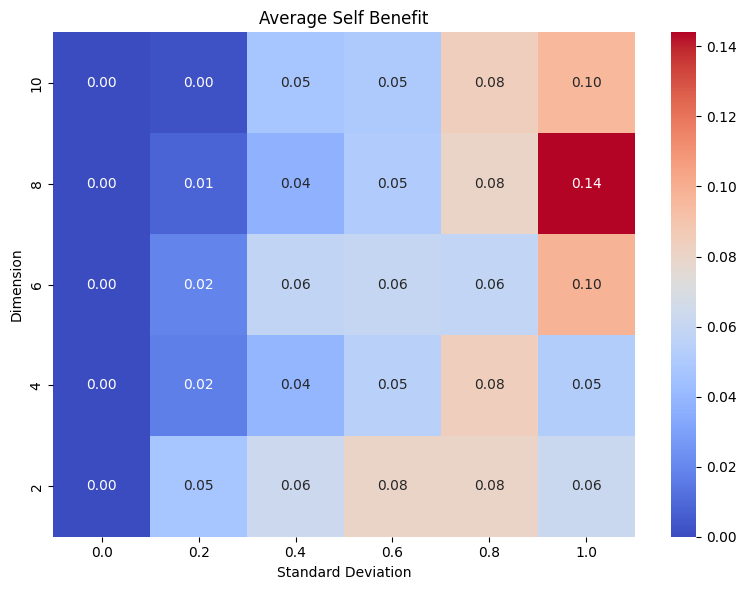

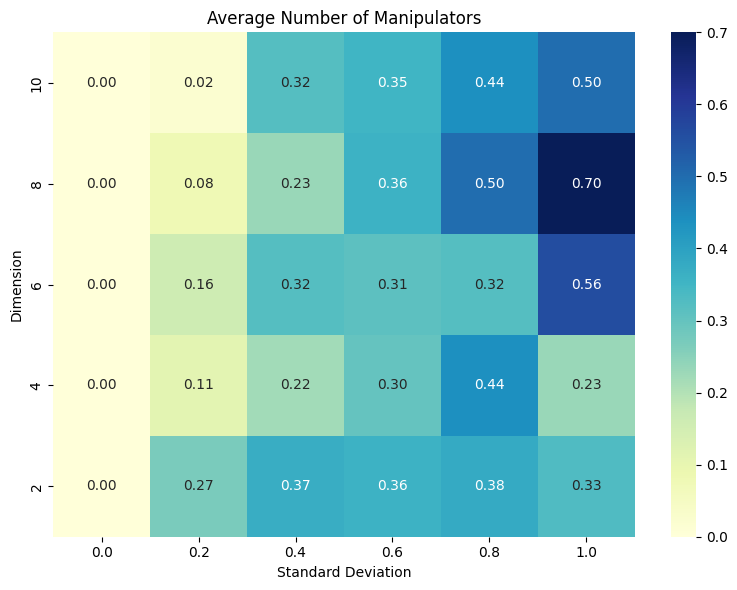

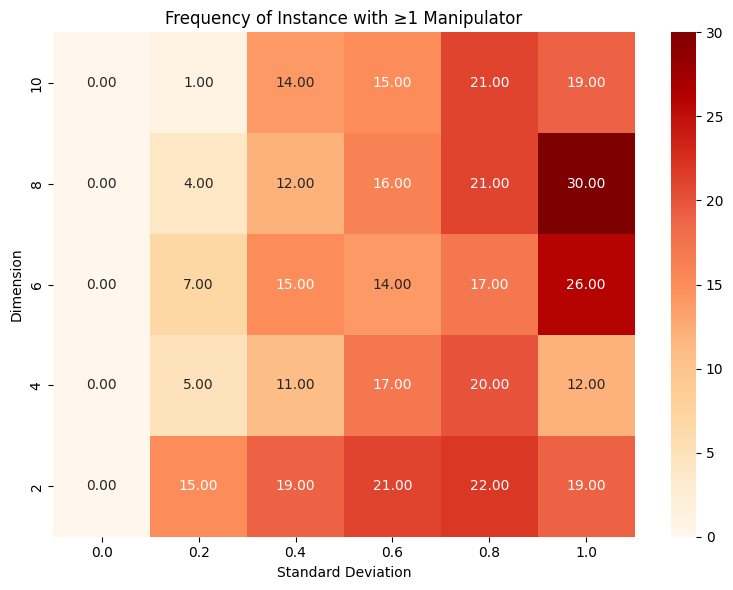

In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("expectations_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("expectations_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "std"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


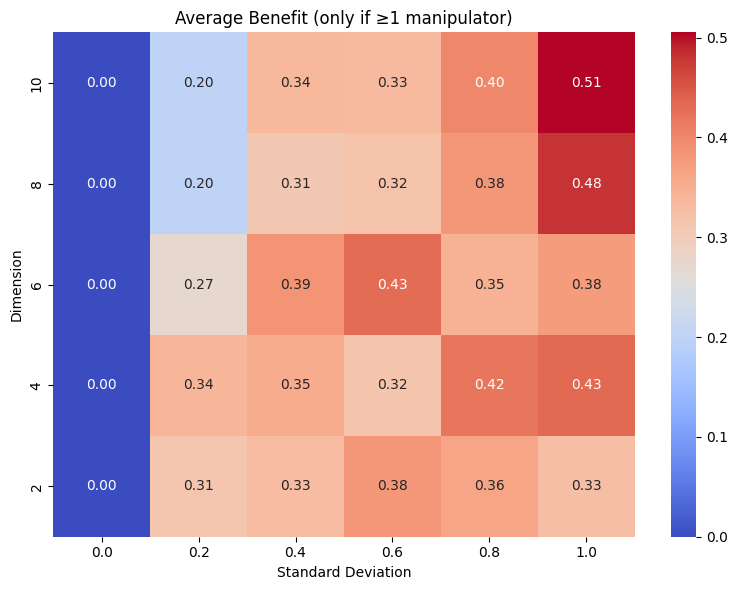

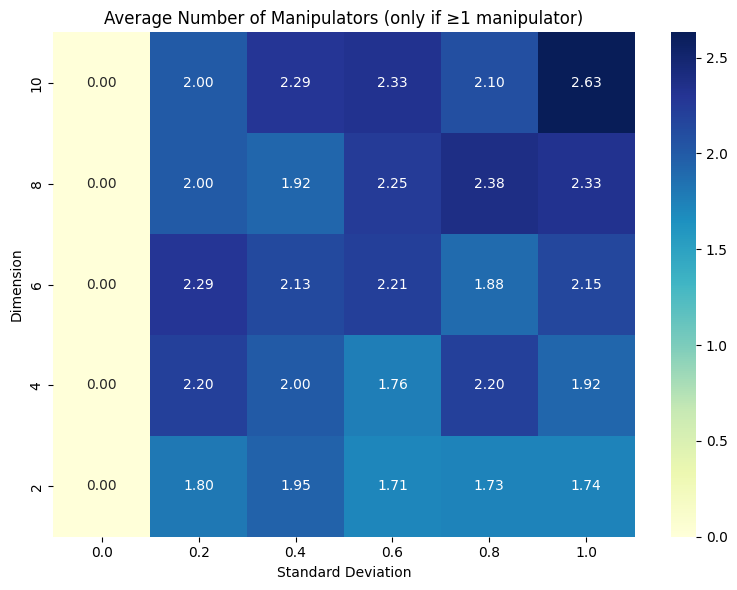

In [41]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "std"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "std"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "std"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "std"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "std"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "std"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="std", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="std", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Fame Euclidean**

In [16]:
data_fame_euclidean_gain = []

n=10
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 3, 5, 10]

for d in tqdm(d_list):
    number_phi = []
    for f in tqdm(f_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref = generate_fame_votes(n, d, 'uniform', f)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_fame_euclidean_gain.append([d, f, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 4/4 [00:02<00:00,  1.41it/s]


In [17]:
df7 = pd.DataFrame(data_fame_euclidean_gain, columns=["dimension", "fame", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df7.to_csv('fame_euclidean_gain.csv', index=False)

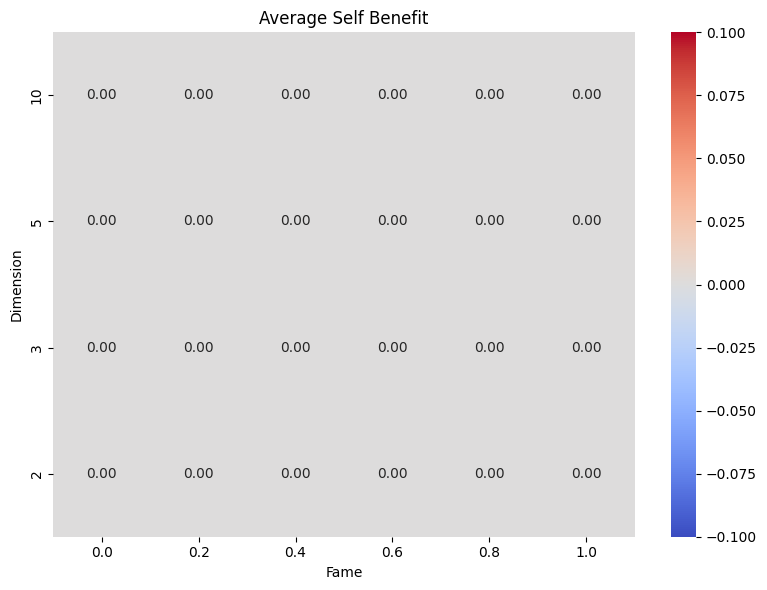

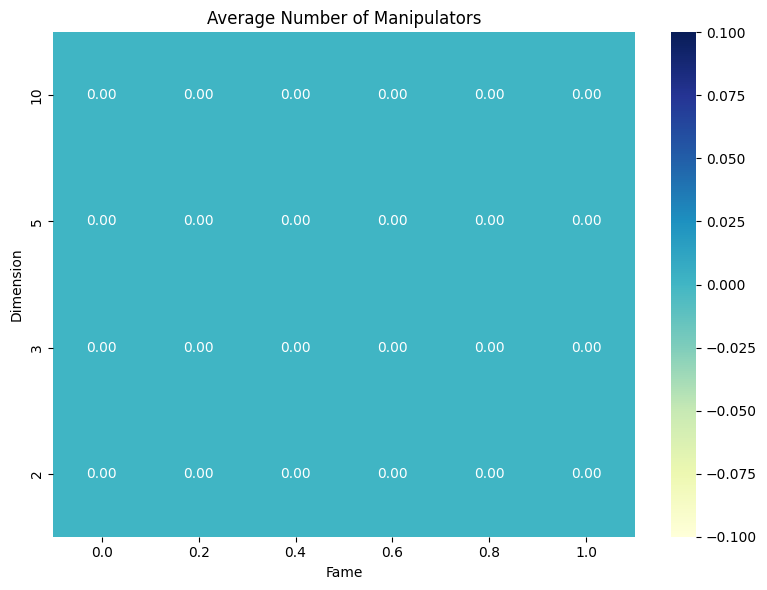

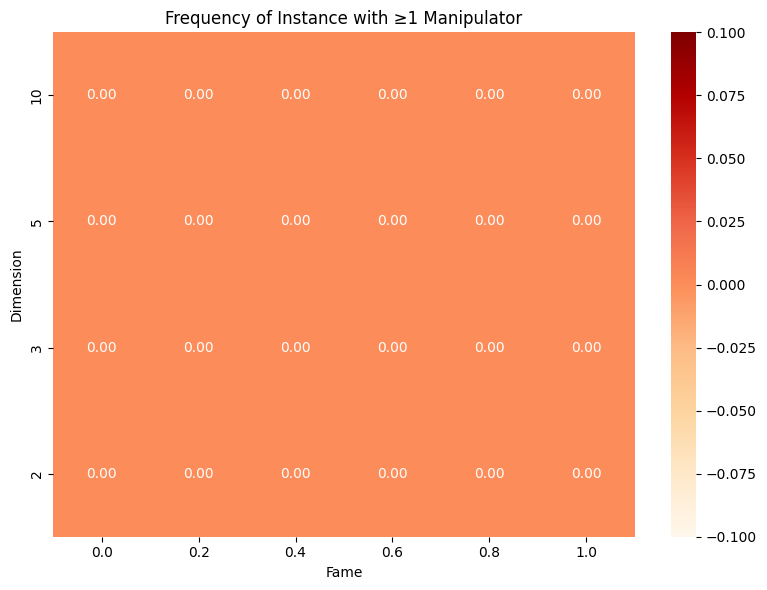

In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("fame_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("fame_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "fame"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Self Benefit")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


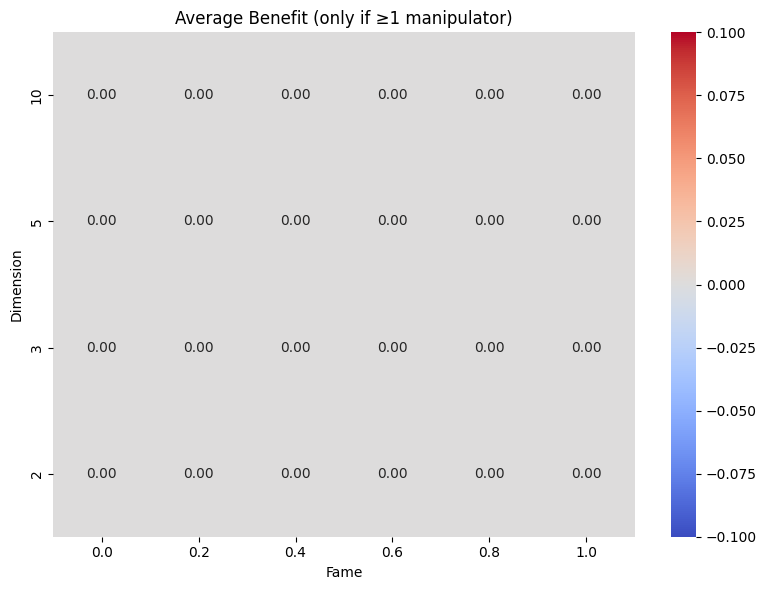

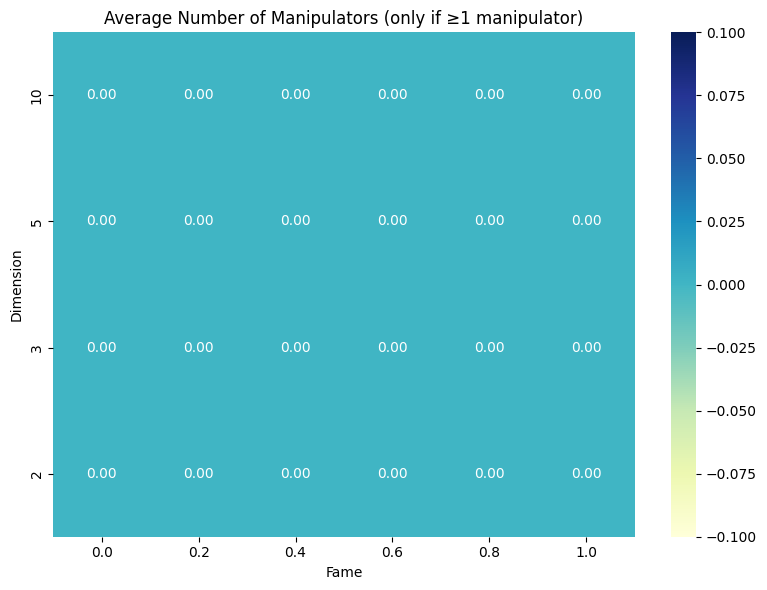

In [37]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "fame"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "fame"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "fame"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "fame"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "fame"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "fame"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="fame", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="fame", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
